# 第 08 章　LoRA 与灾难性遗忘

第 07 章留下两个问题：
1. ΔW 看起来是低秩的。**真的只训练一个低秩的 ΔW（LoRA）就够吗？秩可以低到多少？**
2. 只学合成图形，模型描述真实照片时被"带偏"了。**怎样在学会新任务的同时不忘掉旧能力？**

本章做 6 组对照实验，每组都从**同一个原始模型**出发，只改训练方式：

| 实验 | 训练什么 | 额外措施 |
|---|---|---|
| A | 整个连接器（708 万参数） | 无（即第 07 章） |
| B | LoRA，秩 r=8 | 无 |
| C | LoRA，秩 r=1 | 无 |
| D | 整个连接器 | **回放**：混入真实照片的描述一起训练 |
| E | 整个连接器 | **特征保持**：要求真实照片的图像 token 尽量不变 |

全部跑完约 8 分钟。

In [1]:
import sys, pathlib  # 路径工具
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "vlmlab").exists())  # 找项目根目录
sys.path.insert(0, str(ROOT))  # 加入导入路径

import time  # 计时
import numpy as np  # 数组
import torch  # PyTorch
import matplotlib.pyplot as plt  # 绘图
from vlmlab import *  # 共享工具
from vlmlab.finetune import (QUESTION, shapes_dataset, answer_text, vision_features, Task,  # 第 07 章的代码整理成的函数
                             batch_loss, train, ask, shape_accuracy, answer_nll, LoRALinear)  # 源码见 vlmlab/finetune.py

setup_matplotlib()  # 中文字体
seed_everything(0)  # 固定随机种子
device = get_device()  # mps
processor, model = load_smolvlm(device)  # 加载模型
model.requires_grad_(False)  # 全部冻结，每个实验再按需放开
conn = model.model.connector  # 连接器
base = conn.modality_projection.proj  # 原始线性层
W0 = base.weight.detach().clone()  # 原始权重，每个实验结束后还原

def reset():  # 把模型恢复成原始状态
    conn.modality_projection.proj = base  # 拆掉可能装上的 LoRA
    base.weight.data.copy_(W0)  # 权重还原
    base.weight.requires_grad_(False)  # 重新冻结

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

## 1. 数据
### 1.1 新任务：合成图形（同第 07 章）

In [2]:
train_s = shapes_dataset(320, seed0=1000)  # 训练集
test_s = shapes_dataset(60, seed0=9000)  # 测试集
t = time.time()  # 计时
shape_task = Task(model, processor, QUESTION, vision_features(model, processor, [s[0] for s in train_s]),  # 训练任务：缓存视觉特征
                  [answer_text(s, c) for _, s, c in train_s])  # 和标准答案
print(f"图形任务：{len(shape_task)} 条，准备用时 {time.time()-t:.0f} 秒")  # 打印

图形任务：320 条，准备用时 25 秒


### 1.2 旧能力：描述真实照片
用牛肉饭照片随机裁出 48 张小图（不同位置、不同大小），让**原始模型**描述每一张，它的回答就代表"旧能力"：
- 前 24 张：在实验 D、E 里用于对抗遗忘
- 后 24 张：**只用于评估**，训练时从不出现
- 再加上完整的原始照片（也不参与训练）

生成 48 条描述用时 20 秒；例子：
  In an eye-level, full shot, a bowl of food sits on a wooden table. The bowl is made of woven rattan and is filled
  The image depicts a close-up view of a bowl of food, specifically a type of soup or soup base. The bowl is made of a metallic


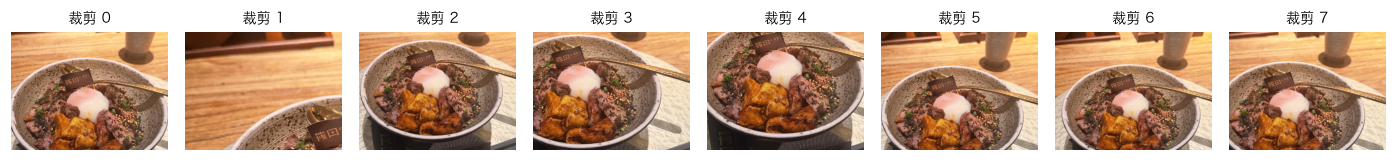

In [3]:
DQ = "Describe this image."  # 描述类问题
photo = load_photo()  # 原始照片
W, H = photo.size  # 宽高
rng = np.random.default_rng(0)  # 随机数
crops = []  # 裁剪图
for i in range(48):  # 裁 48 张
    s = rng.uniform(0.4, 0.9)  # 裁剪比例
    w, h = int(W * s), int(H * s)  # 裁剪尺寸
    x, y = int(rng.integers(0, W - w)), int(rng.integers(0, H - h))  # 左上角
    crops.append(photo.crop((x, y, x + w, y + h)).resize((768, 576)))  # 裁剪并缩小
t = time.time()  # 计时
descs = [ask(model, processor, c, DQ, max_new=30) for c in crops]  # 原始模型的描述（贪心，最多 30 个 token）
crop_feats = vision_features(model, processor, crops)  # 视觉特征
print(f"生成 48 条描述用时 {time.time()-t:.0f} 秒；例子：\n  {descs[0]}\n  {descs[1]}")  # 打印
replay_task = Task(model, processor, DQ, crop_feats[:24], [" " + d + "<end_of_utterance>" for d in descs[:24]])  # 前 24 张：训练用
heldout_task = Task(model, processor, DQ, crop_feats[24:], [" " + d + "<end_of_utterance>" for d in descs[24:]])  # 后 24 张：评估用
photo_desc = ask(model, processor, photo, DQ, max_new=40)  # 完整照片的原始描述
photo_task = Task(model, processor, DQ, vision_features(model, processor, [photo]), [" " + photo_desc + "<end_of_utterance>"])  # 完整照片：评估用
show_images(crops[:8], titles=[f"裁剪 {i}" for i in range(8)], cols=8, size=1.6)  # 看几张

## 2. 怎么衡量"遗忘"？
让模型给**原始模型自己说过的话**打分：计算原始描述的平均负对数似然（NLL）。
- 原始模型打出的分数是基准
- 训练后 NLL 变大 → 模型不再"认同"自己原来的描述 → 发生了遗忘

同时记录：图形任务准确率、完整照片的新描述。

In [4]:
results = {}  # 实验结果
def report(name, n_params, seconds):  # 评估当前模型并记录
    acc, _ = shape_accuracy(model, processor, test_s)  # 新任务准确率
    r = dict(acc=acc, heldout=answer_nll(model, heldout_task).mean().item(),  # 新任务 + 留出裁剪图上的遗忘
             photo=answer_nll(model, photo_task).item(), desc=ask(model, processor, photo, DQ, max_new=40),  # 完整照片
             params=n_params, seconds=seconds)  # 参数量、用时
    results[name] = r  # 保存
    print(f"【{name}】图形准确率 {acc:.0%}｜留出裁剪图 NLL {r['heldout']:.3f}｜完整照片 NLL {r['photo']:.3f}｜可训练参数 {n_params:,}｜训练 {seconds:.0f} 秒")  # 打印
    print(f"  照片描述：{r['desc']}")  # 打印描述

report("原始模型", 0, 0)  # 基准
replay_nll_base = answer_nll(model, replay_task).mean().item()  # 原始模型在 24 张回放裁剪图上的 NLL（实验 D 要用）

【原始模型】图形准确率 22%｜留出裁剪图 NLL 1.354｜完整照片 NLL 1.084｜可训练参数 0｜训练 0 秒
  照片描述：An overhead shot shows a bowl of food, likely a seafood dish, with a poached egg nestled within the ingredients. The bowl is filled with a variety of seafood, including:

- A


## 3. 实验 A：训练整个连接器（第 07 章的做法）

In [5]:
base.weight.requires_grad_(True)  # 放开连接器
t = time.time()  # 计时
log_A = train(model, [base.weight], [(shape_task, 1.0)], steps=120, lr=1e-4)  # 训练
report("A 整个连接器", base.weight.numel(), time.time() - t)  # 评估
W_A = base.weight.detach().clone()  # 保存实验 A 的权重，第 8 节分析
reset()  # 恢复原始模型

  第   0 步  损失 1.6793  已用 0 秒


  第  20 步  损失 0.0045  已用 8 秒


  第  40 步  损失 0.0014  已用 16 秒


  第  60 步  损失 0.0007  已用 24 秒


  第  80 步  损失 0.0008  已用 32 秒


  第 100 步  损失 0.0004  已用 40 秒


  第 119 步  损失 0.0004  已用 48 秒


【A 整个连接器】图形准确率 100%｜留出裁剪图 NLL 1.409｜完整照片 NLL 1.158｜可训练参数 7,077,888｜训练 48 秒
  照片描述：An overhead shot of a traditional Japanese dish, likely a noodle dish, shows a large bowl filled with a variety of ingredients. The bowl is made of a textured, unfinished material, likely wood,


## 4. 实验 B、C：LoRA
把连接器的线性层换成 `LoRALinear`：原权重 $W_0$ 冻结，只训练 $A$（r×12288）和 $B$（576×r）。$B$ 初始为 0，所以刚换上时模型完全不变。

LoRA 的参数少，梯度信号也弱，所以学习率通常比全量训练大一个数量级（这里用 1e-3）。

In [6]:
lora_delta = {}  # 记录每个秩学到的 ΔW
for r in [8, 1]:  # 两个秩
    lora = LoRALinear(base, r=r)  # 包装
    conn.modality_projection.proj = lora  # 装进模型
    t = time.time()  # 计时
    train(model, [lora.A, lora.B], [(shape_task, 1.0)], steps=120, lr=1e-3)  # 只训练 A、B
    report(f"{'B' if r == 8 else 'C'} LoRA r={r}", lora.A.numel() + lora.B.numel(), time.time() - t)  # 评估
    lora_delta[r] = lora.delta_weight().detach().clone()  # 保存 ΔW
    reset()  # 恢复

for r, dW in lora_delta.items():  # 看看 ΔW
    print(f"r={r}：‖ΔW‖/‖W₀‖ = {dW.norm() / W0.norm():.2%}，ΔW 的秩 = {torch.linalg.matrix_rank(dW.float().cpu()).item()}")  # 相对大小与秩

  第   0 步  损失 1.6793  已用 0 秒


  第  20 步  损失 0.0100  已用 8 秒


  第  40 步  损失 0.0021  已用 16 秒


  第  60 步  损失 0.0007  已用 24 秒


  第  80 步  损失 0.0013  已用 32 秒


...

  第  80 步  损失 0.0012  已用 32 秒


  第 100 步  损失 0.0006  已用 40 秒


  第 119 步  损失 0.0006  已用 47 秒


【C LoRA r=1】图形准确率 100%｜留出裁剪图 NLL 1.399｜完整照片 NLL 1.193｜可训练参数 12,864｜训练 47 秒
  照片描述：An overhead shot of a bowl of food, likely a seafood dish, shows a poached egg nestled within a variety of seafood. The egg is positioned in the center of the bowl, surrounded by a
r=8：‖ΔW‖/‖W₀‖ = 5.00%，ΔW 的秩 = 8


r=1：‖ΔW‖/‖W₀‖ = 8.06%，ΔW 的秩 = 1


**观察**：秩为 1 的 LoRA，也就是整个 ΔW 只是**一个向量的外积** $b a^\top$，只有 1.3 万个参数，也能把图形任务学到 100%。新任务需要的"改动方向"极少。

但 LoRA **并没有自动减轻遗忘**：它的遗忘指标不比全量训练小（本机这次运行中，r=8 的照片 NLL 甚至比实验 A 更高），照片描述同样变了。参数少 ≠ 改动小：ΔW 虽然是低秩的，但它作用在**所有**输入上。

## 5. 实验 D：回放（replay）
最直观的办法：训练时把"旧任务"的数据也混进去。这里每一步同时训练一批图形样本和一批照片裁剪图的描述（原始模型的回答当作标准答案），两者损失相加。

In [7]:
base.weight.requires_grad_(True)  # 放开连接器
t = time.time()  # 计时
train(model, [base.weight], [(shape_task, 1.0), (replay_task, 1.0)], steps=120, lr=1e-4)  # 两个任务一起训练
replay_train_nll = answer_nll(model, replay_task).mean().item()  # 回放数据本身的 NLL
report("D 连接器 + 回放", base.weight.numel(), time.time() - t)  # 评估
print(f"回放用的 24 张裁剪图（参与训练）上 NLL = {replay_train_nll:.3f}，原始模型为 {replay_nll_base:.3f}")  # 训练数据上的变化
reset()  # 恢复

  第   0 步  损失 2.8994  已用 1 秒


  第  20 步  损失 0.5434  已用 19 秒


  第  40 步  损失 0.2667  已用 37 秒


  第  60 步  损失 0.0879  已用 55 秒


  第  80 步  损失 0.1231  已用 73 秒


  第 100 步  损失 0.0236  已用 91 秒


  第 119 步  损失 0.0144  已用 108 秒


【D 连接器 + 回放】图形准确率 100%｜留出裁剪图 NLL 1.753｜完整照片 NLL 2.160｜可训练参数 7,077,888｜训练 108 秒
  照片描述：A close-up of a bowl of food, which appears to be a chicken egg cube, in a bowl, with a small knife in the bowl. The egg is in a taco, and
回放用的 24 张裁剪图（参与训练）上 NLL = 0.014，原始模型为 1.249


**观察**：回放数据本身的 NLL 降得远低于原始模型，说明模型把这 24 条描述**背下来了**；而没见过的留出裁剪图 NLL 反而比实验 A 更高。

这是典型的**过拟合**：回放数据太少（24 条），而且是同一张照片，模型学到的是"这些特定句子"，而不是"保持原来的描述能力"。真实项目里回放要用大量、多样的通用数据。

## 6. 实验 E：特征保持
换个思路：我们并不关心语言模型说出哪句话，只要求**连接器对真实照片的输出不变**。语言模型没被改动，只要它收到的图像 token 不变，它的行为就不变。

额外损失：
$$\mathcal{L}_{keep} = \frac{\| \mathrm{conn}(f) - \mathrm{conn}_0(f) \|^2}{\| \mathrm{conn}_0(f) \|^2}$$
其中 $f$ 是 24 张回放裁剪图的视觉特征，$\mathrm{conn}_0$ 是原始连接器。这一项不需要任何文字标注。

In [8]:
with torch.no_grad():  # 不要梯度
    keep_ref = conn(crop_feats[:24].float())  # 原始连接器在 24 张裁剪图上的输出 [24,64,576]
def keep_loss():  # 特征保持损失
    out = conn(crop_feats[:24].float())  # 当前连接器的输出
    return ((out - keep_ref) ** 2).mean() / (keep_ref ** 2).mean()  # 相对平方误差

base.weight.requires_grad_(True)  # 放开连接器
t = time.time()  # 计时
train(model, [base.weight], [(shape_task, 1.0)], steps=120, lr=1e-4, extra_loss=keep_loss)  # 图形任务 + 特征保持
print(f"训练结束时的特征保持损失：{keep_loss().item():.2e}")  # 打印
report("E 连接器 + 特征保持", base.weight.numel(), time.time() - t)  # 评估
W_E = base.weight.detach().clone()  # 保存实验 E 的权重，下一节分析
reset()  # 恢复

  第   0 步  损失 1.6793  已用 0 秒


  第  20 步  损失 0.0099  已用 9 秒


  第  40 步  损失 0.0063  已用 17 秒


  第  60 步  损失 0.0039  已用 25 秒


  第  80 步  损失 0.0029  已用 33 秒


  第 100 步  损失 0.0020  已用 41 秒


  第 119 步  损失 0.0017  已用 49 秒
训练结束时的特征保持损失：1.25e-03


【E 连接器 + 特征保持】图形准确率 100%｜留出裁剪图 NLL 1.361｜完整照片 NLL 1.095｜可训练参数 7,077,888｜训练 49 秒
  照片描述：An overhead shot shows a bowl of food, likely a seafood dish, with a poached egg nestled within the ingredients. The bowl is filled with a variety of seafood, including:

- A


## 7. 汇总

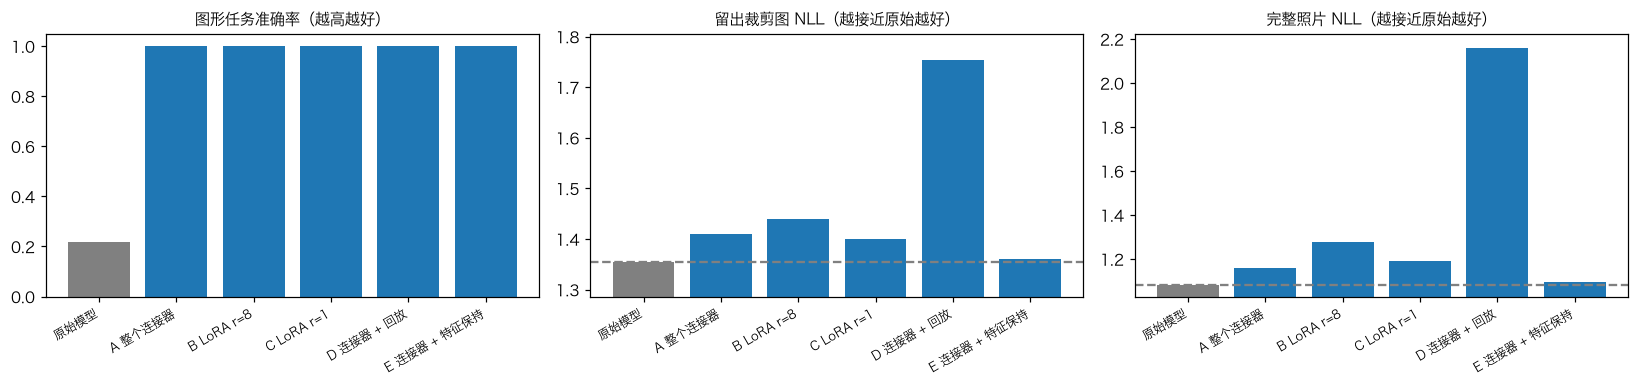

实验                  准确率   留出 NLL   照片 NLL        可训练参数
原始模型                22%    1.354    1.084            0
A 整个连接器            100%    1.409    1.158    7,077,888
B LoRA r=8         100%    1.439    1.276      102,912
C LoRA r=1         100%    1.399    1.193       12,864
D 连接器 + 回放         100%    1.753    2.160    7,077,888
E 连接器 + 特征保持       100%    1.361    1.095    7,077,888


In [9]:
names = list(results)  # 实验名
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))  # 三个指标
for ax, key, title in zip(axes, ["acc", "heldout", "photo"], ["图形任务准确率（越高越好）", "留出裁剪图 NLL（越接近原始越好）", "完整照片 NLL（越接近原始越好）"]):  # 逐个指标
    vals = [results[n][key] for n in names]  # 数值
    ax.bar(range(len(names)), vals, color=["gray"] + ["tab:blue"] * (len(names) - 1))  # 柱状图，原始模型用灰色
    if key != "acc":  # NLL 指标画基准线
        ax.axhline(results["原始模型"][key], color="gray", ls="--")  # 原始模型的数值
        ax.set_ylim(min(vals) * 0.95, max(vals) * 1.03)  # 放大差异
    ax.set_xticks(range(len(names)))  # 横轴
    ax.set_xticklabels(names, rotation=30, ha="right", fontsize=8)  # 实验名
    ax.set_title(title, fontsize=10)  # 标题
plt.tight_layout()  # 调整
plt.show()  # 显示
print(f"{'实验':16s} {'准确率':>6s} {'留出 NLL':>8s} {'照片 NLL':>8s} {'可训练参数':>12s}")  # 表头
for n in names:  # 表格
    r = results[n]  # 结果
    print(f"{n:16s} {r['acc']:>6.0%} {r['heldout']:>8.3f} {r['photo']:>8.3f} {r['params']:>12,}")  # 一行

## 8. 为什么特征保持有效？
连接器是一个 12288→576 的线性映射。图形任务和真实照片的视觉特征落在 12288 维空间的**不同方向**上。特征保持要求 ΔW 在"真实照片方向"上为 0，图形任务只能在其他方向上改。

验证：把实验 A、E 的 ΔW 分别作用在真实照片和图形的特征上，看输出变化多大。

In [10]:
def delta_effect(dW, feats):  # ΔW 让连接器输出变化了多少（相对值）
    x = conn.pixel_shuffle(feats.float(), conn.scale_factor)  # 连接器的输入：pixel shuffle 后 [N,64,12288]
    return ((x @ dW.T).norm() / (x @ W0.T).norm()).item()  # ‖ΔW·x‖ / ‖W₀·x‖

shape_feats_test = vision_features(model, processor, [s[0] for s in test_s[:24]])  # 24 张图形测试图的特征
for name, Wx in [("A 整个连接器", W_A), ("E 特征保持", W_E)]:  # 两个实验
    dW = Wx - W0  # 变化量
    print(f"{name}：真实照片(留出) 输出变化 {delta_effect(dW, crop_feats[24:]):.2%}，图形 输出变化 {delta_effect(dW, shape_feats_test):.2%}")  # 对比

A 整个连接器：真实照片(留出) 输出变化 9.66%，图形 输出变化 30.90%
E 特征保持：真实照片(留出) 输出变化 3.89%，图形 输出变化 28.13%


**观察**：和实验 A 相比，实验 E 的 ΔW 对真实照片输出的改变小了一半多（约 10% → 约 4%），对图形输出的改变却几乎一样大（约 30%）。同一个线性层，学会了"尽量只在需要的地方动手"。

> 局限：这里的"旧能力"只用一张照片的裁剪图来代表，范围很窄。真实的微调需要一组多样的通用图片来做特征保持或回放。

## 小结
| 结论 | 证据 |
|---|---|
| 新任务需要的改动方向极少 | 秩 1 的 LoRA（1.3 万参数）也能学到 100% |
| 参数少 ≠ 不遗忘 | LoRA 的遗忘指标与全量训练相当 |
| 少量回放数据会被背下来 | 回放数据 NLL 远低于原始，留出数据反而更差 |
| 约束"中间表示不变"很有效 | 特征保持：新任务 100%，照片 NLL 几乎回到原始水平，描述与原来一字不差 |

**下一章**：换成更大的 SmolVLM-500M 做对比，以及用 `explore()` 一键探索你自己的照片。